# Reinforcement learning: only rewards

<div class="roadmap"><div class="rm-sofar"><span>So far</span>In every method so far, the data existed before learning began.</div><div class="rm-question"><b>Can a machine learn by trying, as we do?</b><span>Reinforcement learning: act, receive a reward, and adjust what to do next.</span></div><div class="rm-steps"><div class="rm-step"><b>A courier robot</b><span>a depot, a customer, roadworks</span></div><div class="rm-step"><b>Points</b><span>+20 arriving, −10 roadworks, −1 a move</span></div><div class="rm-step"><b>300 tries</b><span>from wandering to the shortest route</span></div><div class="rm-step"><b>The words</b><span>agent, environment, state, action, reward</span></div></div></div>

Reinforcement learning is the one way of learning that has no table at all, and this page uses no hexagons. A courier robot stands at a depot in a small grid of streets and has to reach a customer. Nobody shows it a route. It only receives points: 20 for arriving, minus 10 for driving into roadworks, and minus 1 for every other move, so that short routes pay best.

In [42]:
COLS, ROWS = 7, 5
DEPOT, CUSTOMER = (0, 0), (6, 4)
ROADWORKS = {(2, 0), (2, 1), (2, 2), (4, 4), (4, 3), (4, 2)}
MOVES = [(0, 1), (1, 0), (0, -1), (-1, 0)]          # north, east, south, west


def drive(place, move):
    """What the street grid answers to one move: the new place, the points for it, and whether the robot has arrived."""
    nxt = (place[0] + MOVES[move][0], place[1] + MOVES[move][1])
    if nxt in ROADWORKS:
        return place, -10, False                        # drives into roadworks and stays where it was
    if not (0 <= nxt[0] < COLS and 0 <= nxt[1] < ROWS):
        return place, -1, False                         # the edge of the map: a wasted move
    return nxt, (20 if nxt == CUSTOMER else -1), nxt == CUSTOMER


def learn(tries=300, seed=0, max_moves=200):
    """Trial and error. The robot keeps one number for every place and move: the points it expects from there on.
    After each move it corrects that number a little (the method is called Q-learning)."""
    rng = np.random.default_rng(seed)
    expect = np.zeros((COLS, ROWS, 4))
    totals, routes = [], []
    for t in range(tries):
        curious = max(0.02, 1 - t / (0.6 * tries))     # share of moves made at random: high at first, then falling
        place, total, route = DEPOT, 0, [DEPOT]
        for _ in range(max_moves):
            move = int(rng.integers(4)) if rng.random() < curious else int(np.argmax(expect[place]))
            nxt, points, arrived = drive(place, move)
            best_next = 0.0 if arrived else expect[nxt].max()
            expect[place][move] += 0.5 * (points + 0.95 * best_next - expect[place][move])
            place, total = nxt, total + points
            route.append(place)
            if arrived:
                break
        totals.append(total)
        routes.append(route)
    return np.array(totals), routes, expect


def learned_route(expect, max_moves=60):
    """The route the robot drives when it always takes the move it expects most from."""
    place, route = DEPOT, [DEPOT]
    for _ in range(max_moves):
        place, _, arrived = drive(place, int(np.argmax(expect[place])))
        route.append(place)
        if arrived:
            break
    return route


totals, routes, expect = learn()
final = learned_route(expect)
print(f"try   1: {len(routes[0]) - 1:3d} moves, {totals[0]:+5d} points")
for t in (5, 20, 60, 150, 300):
    print(f"try {t:3d}: {len(routes[t - 1]) - 1:3d} moves, {totals[t - 1]:+5d} points")
print(f"after 300 tries, without random moves: {len(final) - 1} moves, {20 - (len(final) - 2):+d} points. The shortest safe route has 14 moves.")

repeats = np.array([len(learned_route(learn(seed=s)[2])) - 1 for s in range(50)])
print(f"Repeated 50 times with other random numbers: the learned route is the shortest possible in {int((repeats == 14).sum())} of 50.")
h.note("courier", {"first_moves": len(routes[0]) - 1, "first_points": int(totals[0]), "final_moves": len(final) - 1,
                   "final_points": 20 - (len(final) - 2), "shortest_in_50": int((repeats == 14).sum()), "tries": 300}, SAVE)

try   1: 152 moves,  -275 points
try   5: 114 moves,  -228 points
try  20: 166 moves,  -280 points
try  60:  28 moves,   -25 points
try 150:  19 moves,    +2 points
try 300:  14 moves,    +7 points
after 300 tries, without random moves: 14 moves, +7 points. The shortest safe route has 14 moves.


Repeated 50 times with other random numbers: the learned route is the shortest possible in 50 of 50.


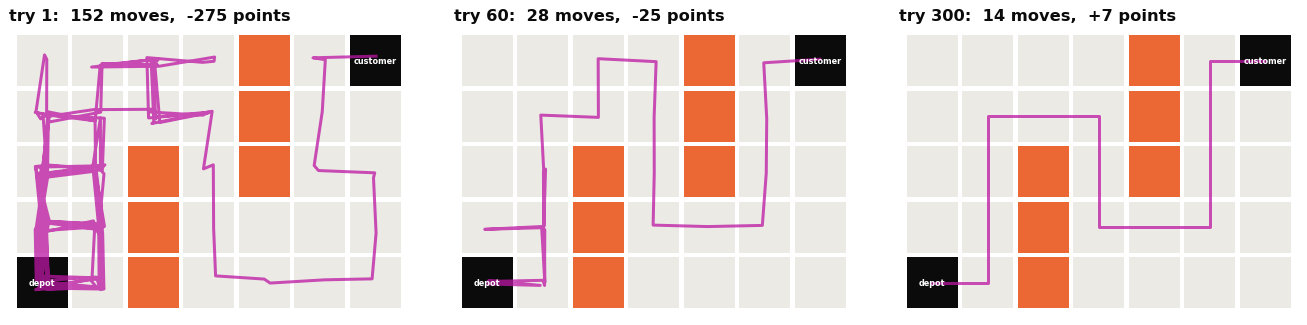

In [43]:
def draw_grid(ax, route=None, title=""):
    for col in range(COLS):
        for row in range(ROWS):
            works = (col, row) in ROADWORKS
            ax.add_patch(plt.Rectangle((col - 0.46, row - 0.46), 0.92, 0.92, fc="#eb6834" if works else "#eceae4", ec="none"))
    for (col, row), word in ((DEPOT, "depot"), (CUSTOMER, "customer")):
        ax.add_patch(plt.Rectangle((col - 0.46, row - 0.46), 0.92, 0.92, fc=h.INK, ec="none"))
        ax.text(col, row, word, color="white", ha="center", va="center", fontsize=6.5, fontweight="bold", zorder=6)
    if route is not None:
        shift = 0.13 if len(route) > 60 else (0.05 if len(route) > 16 else 0.0)      # for drawing only: repeated moves stay visible
        pts = np.asarray(route, float) + np.random.default_rng(0).uniform(-shift, shift, (len(route), 2))
        ax.plot(pts[:, 0], pts[:, 1], color=h.ACCENT, lw=2.4, alpha=0.75, solid_joinstyle="round", zorder=4)
    ax.set_xlim(-0.6, COLS - 0.4), ax.set_ylim(-0.6, ROWS - 0.4)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.set_title(title, fontsize=12)


def draw_try(t):
    """One frame of the animation: the route of try t on the street grid, and the points of all tries so far."""
    fig, (ax, bx) = plt.subplots(1, 2, figsize=(9.6, 4.0), gridspec_kw={"width_ratios": [1.55, 1]})
    draw_grid(ax, routes[t - 1], f"try {t}:  {len(routes[t - 1]) - 1} moves,  {totals[t - 1]:+d} points")
    bx.plot(np.arange(1, t + 1), totals[:t], color=h.MUTED, lw=1.2)
    bx.scatter([t], [totals[t - 1]], s=70, color=h.ACCENT, zorder=3)
    bx.axhline(7, color=h.INK, lw=1, ls=":")
    bx.text(len(totals), 12, "best possible: +7", ha="right", va="bottom", fontsize=9)
    bx.set_xlim(0, len(totals) + 5), bx.set_ylim(min(totals.min(), -100) - 20, 45)
    bx.set_xlabel("try")
    bx.set_title("points per try", fontsize=12)
    fig.tight_layout()
    return fig


fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, t in zip(axes, (1, 60, 300)):
    draw_grid(ax, routes[t - 1], f"try {t}:  {len(routes[t - 1]) - 1} moves,  {totals[t - 1]:+d} points")
plt.tight_layout()
h.save(fig, "x_courier_tries.png", SAVE)
plt.show()
if SAVE:    # the animation for the slides
    h.frames_gif(draw_try, [1, 5, 20, 60, 150, 300], "x_courier.gif", ms=1300)
    h.frames(draw_try, [1, 2, 3, 5, 10, 20, 40, 60, 100, 150, 200, 300], "courier")

<div class="frames" data-name="courier" data-labels="try 1|try 2|try 3|try 5|try 10|try 20|try 40|try 60|try 100|try 150|try 200|try 300"></div>

*The route of the robot on one try (left) and the points of all tries so far (right).*

> **What did we just see?** On its first try the robot wanders and collects a large negative score. Nobody tells it which move was wrong; it only notices which moves were followed by more points, and repeats those more often. After a few hundred tries it drives the shortest safe route. Three things differ from everything else on this site. There are no labelled examples, only points. The data did not exist beforehand: the robot's own moves produced them. And the robot had to make random moves at first, to find out what pays, and fewer of them later, to use what it found.

In the words of the lecture: the robot is the **agent**, the street grid is the **environment**, the place where the robot stands is the **state**, a move is an **action**, and the points are the **reward**.